In [1]:
import sys, platform, subprocess
import importlib.metadata as md
import torch

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA version torch was built with:", torch.version.cuda)

if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    free, total = torch.cuda.mem_get_info()
    print("GPU:", props.name)
    print(f"Total VRAM: {total / 1024**3:.1f} GiB | Free now: {free / 1024**3:.1f} GiB")
    print("bf16 supported:", torch.cuda.is_bf16_supported())
else:
    print("NO GPU DETECTED - fix the runtime type before continuing.")

for pkg in ["diffusers", "transformers", "accelerate", "safetensors", "gradio", "numpy", "pillow"]:
    try:
        print(f"{pkg}: {md.version(pkg)}")
    except md.PackageNotFoundError:
        print(f"{pkg}: NOT INSTALLED")

print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)

Python: 3.13.16
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
PyTorch: 2.14.1+cu130
CUDA available: True
CUDA version torch was built with: 13.0
GPU: Tesla T4
Total VRAM: 14.6 GiB | Free now: 14.5 GiB
bf16 supported: True
diffusers: 0.42.1
transformers: 5.22.1
accelerate: 1.15.0
safetensors: 0.8.0
gradio: 6.31.0
numpy: 2.4.6
pillow: 11.3.0
Sat Nov 21 06:42:50 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+=====

In [2]:
import time
import torch
from diffusers import ControlNetModel, StableDiffusionControlNetPipeline, UniPCMultistepScheduler

BASE_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"
CONTROLNET_ID = "lllyasviel/control_v11p_sd15_scribble"

start = time.time()

# 1) Load the control branch weights in half precision (fp16 = 2 bytes/param instead of 4)
controlnet = ControlNetModel.from_pretrained(CONTROLNET_ID, torch_dtype=torch.float16)

# 2) Load the base pipeline and attach the ControlNet to it
pipe = StableDiffusionControlNetPipeline.from_pretrained(
    BASE_ID, controlnet=controlnet, torch_dtype=torch.float16
)

# 3) Choose the scheduler (the noise-removal update rule)
pipe.scheduler = UniPCMultistepScheduler.from_config(pipe.scheduler.config)

# 4) Move everything to the GPU
pipe.to("cuda")
print(f"Loaded in {time.time() - start:.0f}s")

# 5) Inventory of components
for name, comp in pipe.components.items():
    if isinstance(comp, torch.nn.Module):
        n_params = sum(p.numel() for p in comp.parameters()) / 1e6
        print(f"{name:18s} {type(comp).__name__:28s} {n_params:8.1f}M params")
    else:
        print(f"{name:18s} {type(comp).__name__}")

print(f"VRAM allocated: {torch.cuda.memory_allocated() / 1024**3:.2f} GiB")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/999 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.45GB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

... (2 outputs left out)

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loaded in 113s
vae                AutoencoderKL                    83.7M params
text_encoder       CLIPTextModel                   123.1M params
tokenizer          CLIPTokenizer
unet               UNet2DConditionModel            859.5M params
controlnet         ControlNetModel                 361.3M params
scheduler          UniPCMultistepScheduler
safety_checker     StableDiffusionSafetyChecker    304.0M params
feature_extractor  CLIPImageProcessor
image_encoder      NoneType
VRAM allocated: 3.26 GiB


There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

Run A: 15.3s | Run B: 13.4s | peak VRAM: 6.57 GiB
NSFW flags: [False], [False]
Identical: True | max pixel difference: 0
{
  "prompt": "A floating fantasy castle above the clouds, cinematic lighting, detailed concept art",
  "negative_prompt": "blurry, low quality, distorted, deformed",
  "seed": 42,
  "steps": 25,
  "guidance_scale": 7.5,
  "height": 512,
  "width": 512
}


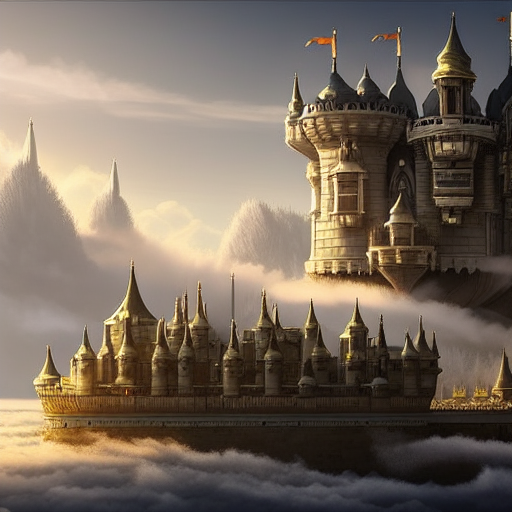

In [3]:
import time, json
import numpy as np
import torch
from diffusers import StableDiffusionPipeline

txt2img = StableDiffusionPipeline.from_pipe(pipe)  # same weights, no ControlNet

config = {
    "prompt": "A floating fantasy castle above the clouds, cinematic lighting, detailed concept art",
    "negative_prompt": "blurry, low quality, distorted, deformed",
    "seed": 42,
    "steps": 25,
    "guidance_scale": 7.5,
    "height": 512,
    "width": 512,
}

def run_baseline(cfg: dict):
    generator = torch.Generator(device="cuda").manual_seed(cfg["seed"])
    torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()
    t0 = time.time()
    result = txt2img(
        prompt=cfg["prompt"],
        negative_prompt=cfg["negative_prompt"],
        num_inference_steps=cfg["steps"],
        guidance_scale=cfg["guidance_scale"],
        height=cfg["height"],
        width=cfg["width"],
        generator=generator,
    )
    torch.cuda.synchronize()
    elapsed = time.time() - t0
    peak_gib = torch.cuda.max_memory_allocated() / 1024**3
    return result.images[0], result.nsfw_content_detected, elapsed, peak_gib

image_a, nsfw_a, t_a, peak_a = run_baseline(config)
image_b, nsfw_b, t_b, peak_b = run_baseline(config)   # identical settings

diff = np.abs(np.asarray(image_a, dtype=np.int16) - np.asarray(image_b, dtype=np.int16))
print(f"Run A: {t_a:.1f}s | Run B: {t_b:.1f}s | peak VRAM: {peak_b:.2f} GiB")
print(f"NSFW flags: {nsfw_a}, {nsfw_b}")
print(f"Identical: {diff.max() == 0} | max pixel difference: {diff.max()}")

image_a.save("baseline_seed42.png")
print(json.dumps(config, indent=2))
display(image_a)

In [4]:
from huggingface_hub import hf_hub_download

readme_path = hf_hub_download("lllyasviel/control_v11p_sd15_scribble", "README.md")
with open(readme_path, encoding="utf-8") as f:
    lines = f.read().splitlines()

keywords = ["white", "black", "scribble", "resize", "detector", "processor", "conditioning"]
for i, line in enumerate(lines):
    if any(k in line.lower() for k in keywords):
        print(f"{i:3d}: {line[:200]}")

README.md:   0%|          | 0.00/16.5k [00:00<?, ?B/s]

  9: duplicated_from: ControlNet-1-1-preview/control_v11p_sd15_scribble
 12: # Controlnet - v1.1 - *Scribble Version*
 17: This checkpoint is a conversion of [the original checkpoint](https://huggingface.co/lllyasviel/ControlNet-v1-1/blob/main/control_v11p_sd15_scribble.pth) into `diffusers` format.
 28: This checkpoint corresponds to the ControlNet conditioned on **Scribble images**
 67: **Note**: If you want to process an image to create the auxiliary conditioning, external dependencies are required as shown below:
 91: from controlnet_aux import PidiNetDetector, HEDdetector
 99: checkpoint = "lllyasviel/control_v11p_sd15_scribble"
102:     "https://huggingface.co/lllyasviel/control_v11p_sd15_scribble/resolve/main/images/input.png"
107: processor = HEDdetector.from_pretrained('lllyasviel/Annotators')
109: control_image = processor(image, scribble=True)
135: on a different type of conditioning:
139: |[lllyasviel/control_v11p_sd15_canny](https://huggingface.co/lllyasviel/control_v11p_s

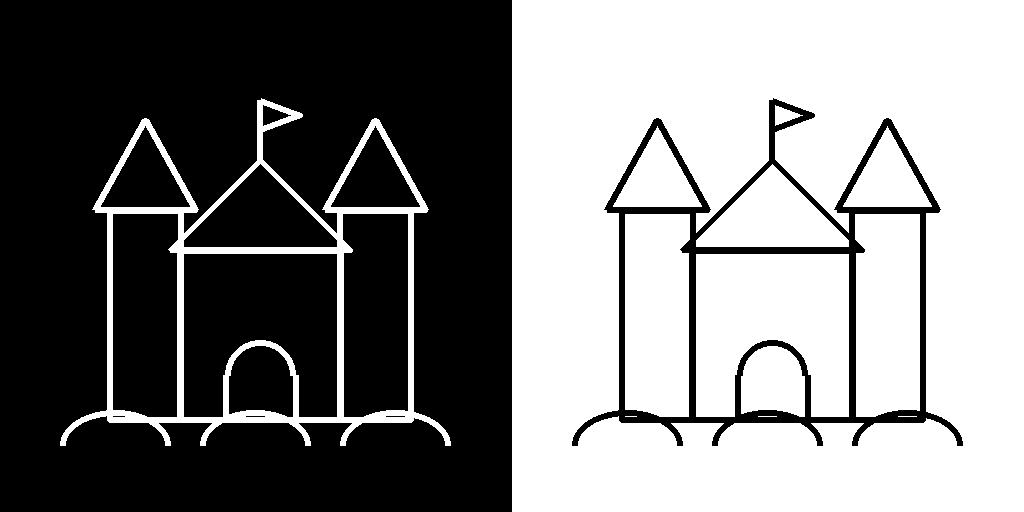

sizes: (512, 512) (512, 512) | mode: RGB


In [5]:
from PIL import Image, ImageDraw, ImageOps

def make_castle_sketch(size: int = 512, line_px: int = 6) -> Image.Image:
    """Return a white-line-on-black castle sketch as an RGB image."""
    img = Image.new("L", (size, size), 0)          # black background
    d = ImageDraw.Draw(img)

    def closed(points):                             # draw a closed outline with lines
        d.line(points + [points[0]], fill=255, width=line_px, joint="curve")

    closed([(180, 250), (340, 250), (340, 420), (180, 420)])   # central keep
    closed([(110, 210), (180, 210), (180, 420), (110, 420)])   # left tower
    closed([(340, 210), (410, 210), (410, 420), (340, 420)])   # right tower
    closed([(95, 210), (145, 120), (195, 210)])                # left roof
    closed([(325, 210), (375, 120), (425, 210)])               # right roof
    closed([(170, 250), (260, 160), (350, 250)])               # central roof
    d.line([(260, 160), (260, 100)], fill=255, width=line_px)  # flag pole
    closed([(260, 100), (300, 115), (260, 130)])               # flag
    d.arc([225, 340, 295, 410], 180, 360, fill=255, width=line_px)  # door arch
    d.line([(225, 375), (225, 420)], fill=255, width=line_px)
    d.line([(295, 375), (295, 420)], fill=255, width=line_px)
    for x in (60, 200, 340):                                   # cloud bumps below
        d.arc([x, 410, x + 110, 480], 180, 360, fill=255, width=line_px)
    return img.convert("RGB")

sketch_wob = make_castle_sketch()               # white lines on black
sketch_bow = ImageOps.invert(sketch_wob)        # black lines on white (inverted)

sketch_wob.save("sketch_white_on_black.png")
sketch_bow.save("sketch_black_on_white.png")

panel = Image.new("RGB", (1024, 512))
panel.paste(sketch_wob, (0, 0))
panel.paste(sketch_bow, (512, 0))
display(panel)
print("sizes:", sketch_wob.size, sketch_bow.size, "| mode:", sketch_wob.mode)

In [6]:
import time
import torch

def dtype_report(pipeline) -> None:
    """Print the weight dtype of each neural-network component in the pipeline."""
    for name, comp in pipeline.components.items():
        if isinstance(comp, torch.nn.Module):
            dtypes = {p.dtype for p in comp.parameters()}
            print(f"{name:18s} {sorted(str(d) for d in dtypes)}")

def run_controlled(sketch, scale: float = 1.0, cfg: dict = None):
    """Generate with the sketch as ControlNet input. Returns (image, seconds, peak_vram_gib)."""
    cfg = cfg or config
    generator = torch.Generator(device="cuda").manual_seed(cfg["seed"])
    torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()
    t0 = time.time()
    result = pipe(
        prompt=cfg["prompt"],
        negative_prompt=cfg["negative_prompt"],
        image=sketch,
        num_inference_steps=cfg["steps"],
        guidance_scale=cfg["guidance_scale"],
        controlnet_conditioning_scale=float(scale),
        height=cfg["height"],
        width=cfg["width"],
        generator=generator,
    )
    torch.cuda.synchronize()
    elapsed = time.time() - t0
    peak_gib = torch.cuda.max_memory_allocated() / 1024**3
    return result.images[0], elapsed, peak_gib

There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


dtype check (all should be float16):
vae                ['torch.float16']
text_encoder       ['torch.float16']
unet               ['torch.float16']
controlnet         ['torch.float16']
safety_checker     ['torch.float16']


  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

baseline (no sketch): 4.7s | peak 3.87 GiB | NSFW flag: [False]
white-on-black:       6.6s | peak 3.91 GiB
black-on-white:       6.6s | peak 3.91 GiB


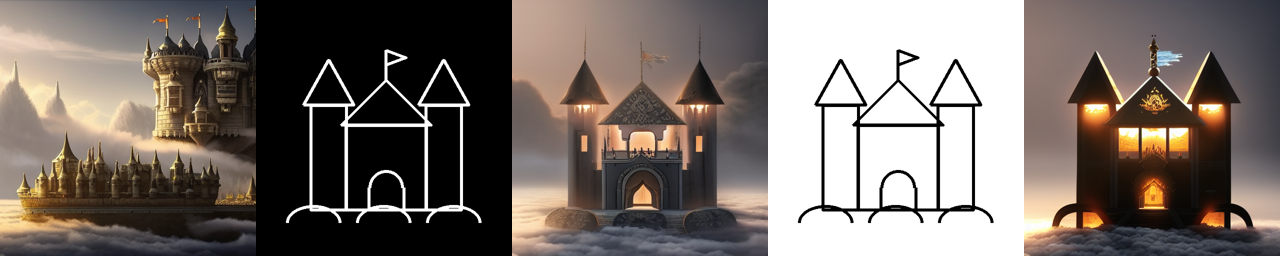

In [7]:
import torch
from PIL import Image
from diffusers import StableDiffusionPipeline

# Text-only pipeline sharing the same weights, with the dtype stated explicitly this time
txt2img = StableDiffusionPipeline.from_pipe(pipe, torch_dtype=torch.float16)
print("dtype check (all should be float16):")
dtype_report(pipe)

_ = run_baseline(config)                                   # warm-up, discarded
base_img, nsfw, t_base, m_base = run_baseline(config)      # fp16 baseline, no sketch
wob_img, t_wob, m_wob = run_controlled(sketch_wob)         # white-on-black sketch
bow_img, t_bow, m_bow = run_controlled(sketch_bow)         # black-on-white sketch

print(f"baseline (no sketch): {t_base:.1f}s | peak {m_base:.2f} GiB | NSFW flag: {nsfw}")
print(f"white-on-black:       {t_wob:.1f}s | peak {m_wob:.2f} GiB")
print(f"black-on-white:       {t_bow:.1f}s | peak {m_bow:.2f} GiB")

tiles = [base_img, sketch_wob, wob_img, sketch_bow, bow_img]
grid = Image.new("RGB", (256 * len(tiles), 256))
for i, im in enumerate(tiles):
    grid.paste(im.resize((256, 256)), (256 * i, 0))
base_img.save("baseline_fp16_seed42.png")
wob_img.save("controlled_white_on_black.png")
bow_img.save("controlled_black_on_white.png")
display(grid)

  0%|          | 0/25 [00:00<?, ?it/s]

scale 0.0: 6.4s


  0%|          | 0/25 [00:00<?, ?it/s]

scale 0.5: 6.7s


  0%|          | 0/25 [00:00<?, ?it/s]

scale 1.0: 6.9s


  0%|          | 0/25 [00:00<?, ?it/s]

scale 1.5: 6.7s
scale 0.0 vs text-only baseline, max pixel difference: 0
scales left to right: [0.0, 0.5, 1.0, 1.5]


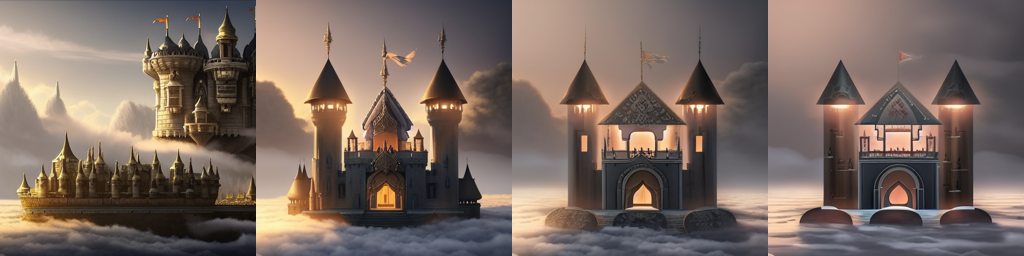

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

seeds: [1, 7, 123] | top row: white-on-black | bottom row: black-on-white


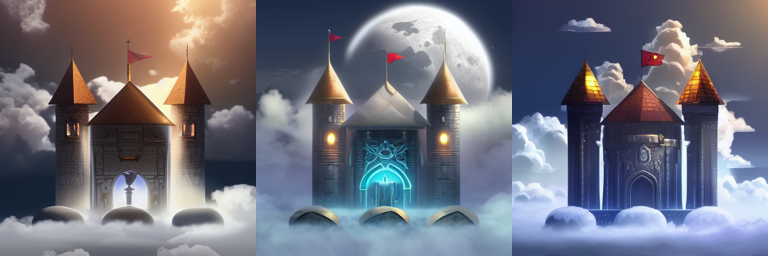

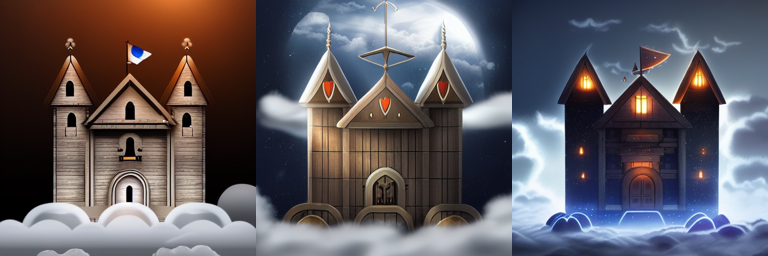

In [8]:
import numpy as np
from PIL import Image

def tile_row(images, size=256):
    row = Image.new("RGB", (size * len(images), size))
    for i, im in enumerate(images):
        row.paste(im.resize((size, size)), (size * i, 0))
    return row

# Part 1: control-strength sweep (white-on-black sketch, seed 42)
scales = [0.0, 0.5, 1.0, 1.5]
sweep = []
for s in scales:
    img, t, m = run_controlled(sketch_wob, scale=s)
    sweep.append(img)
    print(f"scale {s}: {t:.1f}s")
diff0 = np.abs(np.asarray(sweep[0], dtype=np.int16) - np.asarray(base_img, dtype=np.int16)).max()
print("scale 0.0 vs text-only baseline, max pixel difference:", diff0)
print("scales left to right:", scales)
display(tile_row(sweep))

# Part 2: polarity robustness across seeds
seeds = [1, 7, 123]
rows_w, rows_b = [], []
for sd in seeds:
    cfg = dict(config, seed=sd)
    rows_w.append(run_controlled(sketch_wob, 1.0, cfg)[0])
    rows_b.append(run_controlled(sketch_bow, 1.0, cfg)[0])
print("seeds:", seeds, "| top row: white-on-black | bottom row: black-on-white")
display(tile_row(rows_w))
display(tile_row(rows_b))

Preprocessing mismatch vs sketch_wob: 0.0000%
[empty prompt] -> Please enter a text prompt.
[blank sketch] -> The sketch looks empty. Draw darker or thicker lines on a light background.


  0%|          | 0/25 [00:00<?, ?it/s]

{
  "prompt": "A floating fantasy castle above the clouds, cinematic lighting, detailed concept art, highly detailed",
  "negative_prompt": "blurry, low quality, distorted, deformed",
  "style": "Cinematic concept art",
  "seed": 42,
  "steps": 25,
  "guidance_scale": 7.5,
  "controlnet_conditioning_scale": 1.0,
  "size": "512x512",
  "seconds": 5.89,
  "peak_vram_gib": 3.91,
  "base_model": "stable-diffusion-v1-5/stable-diffusion-v1-5",
  "controlnet": "lllyasviel/control_v11p_sd15_scribble"
}


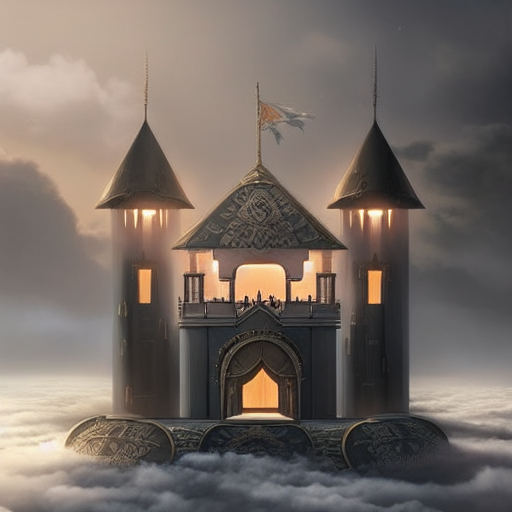

In [9]:
import json, os, random, time
import numpy as np
import torch
from PIL import Image

STYLE_PRESETS = {
    "None": "",
    "Cinematic concept art": ", cinematic lighting, detailed concept art, highly detailed",
    "Watercolor": ", soft watercolor painting, pastel colors, paper texture",
    "Pixel art": ", pixel art, 16-bit video game style",
    "Photorealistic": ", photorealistic, natural lighting, 35mm photo",
}
DEFAULT_NEGATIVE = "blurry, low quality, distorted, deformed"

def prepare_control_image(sketch, size: int = 512, dark_threshold: int = 128) -> Image.Image:
    """Turn a user sketch (dark strokes on light canvas) into white strokes on black, size x size RGB."""
    if isinstance(sketch, dict):                       # Gradio Sketchpad/ImageEditor value
        sketch = sketch.get("composite")
    if sketch is None:
        raise ValueError("Please draw a sketch or upload one first.")
    img = Image.fromarray(sketch) if isinstance(sketch, np.ndarray) else sketch
    if img.mode in ("RGBA", "LA", "P"):                # flatten transparency onto white
        img = img.convert("RGBA")
        canvas = Image.new("RGBA", img.size, (255, 255, 255, 255))
        img = Image.alpha_composite(canvas, img)
    gray = np.asarray(img.convert("L").resize((size, size), Image.LANCZOS))
    strokes = gray < dark_threshold
    if strokes.mean() < 0.002:
        raise ValueError("The sketch looks empty. Draw darker or thicker lines on a light background.")
    return Image.fromarray(np.where(strokes, 255, 0).astype(np.uint8)).convert("RGB")

def generate(sketch, prompt: str, style: str, steps: int, control_scale: float,
             seed: int, guidance: float = 7.5, out_dir: str = "outputs"):
    """Run sketch+text generation. Returns (image, control_image, settings dict)."""
    if not prompt or not prompt.strip():
        raise ValueError("Please enter a text prompt.")
    if not 10 <= int(steps) <= 50:
        raise ValueError("Inference steps must be between 10 and 50.")
    if not 0.0 <= float(control_scale) <= 2.0:
        raise ValueError("Control strength must be between 0.0 and 2.0.")
    if style not in STYLE_PRESETS:
        raise ValueError(f"Unknown style: {style}")

    control = prepare_control_image(sketch)
    seed = int(seed)
    if seed < 0:
        seed = random.randint(0, 2**31 - 1)            # seed -1 means "pick one for me"
    full_prompt = prompt.strip() + STYLE_PRESETS[style]

    generator = torch.Generator(device="cuda").manual_seed(seed)
    torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    with torch.inference_mode():
        out = pipe(
            prompt=full_prompt, negative_prompt=DEFAULT_NEGATIVE, image=control,
            num_inference_steps=int(steps), guidance_scale=float(guidance),
            controlnet_conditioning_scale=float(control_scale),
            height=512, width=512, generator=generator,
        )
    elapsed = time.time() - t0
    if out.nsfw_content_detected and out.nsfw_content_detected[0]:
        raise RuntimeError("The safety checker blocked this result. Try a different seed or prompt.")

    settings = {
        "prompt": full_prompt, "negative_prompt": DEFAULT_NEGATIVE, "style": style,
        "seed": seed, "steps": int(steps), "guidance_scale": float(guidance),
        "controlnet_conditioning_scale": float(control_scale), "size": "512x512",
        "seconds": round(elapsed, 2),
        "peak_vram_gib": round(torch.cuda.max_memory_allocated() / 1024**3, 2),
        "base_model": BASE_ID, "controlnet": CONTROLNET_ID,
    }
    os.makedirs(out_dir, exist_ok=True)
    stamp = time.strftime("%Y%m%d_%H%M%S")
    out.images[0].save(f"{out_dir}/{stamp}_seed{seed}.png")
    with open(f"{out_dir}/{stamp}_seed{seed}.json", "w") as f:
        json.dump(settings, f, indent=2)
    return out.images[0], control, settings

# --- Tests ---
# 1) preprocessing: a black-on-white sketch should convert to (almost exactly) our white-on-black one
conv = prepare_control_image(sketch_bow)
mismatch = np.mean(np.asarray(conv) != np.asarray(sketch_wob))
print(f"Preprocessing mismatch vs sketch_wob: {mismatch:.4%}")

# 2) friendly errors
for label, kwargs in {
    "empty prompt": dict(sketch=sketch_bow, prompt="  "),
    "blank sketch": dict(sketch=Image.new("RGB", (512, 512), "white"), prompt="a castle"),
}.items():
    try:
        generate(style="None", steps=25, control_scale=1.0, seed=42, **kwargs)
    except ValueError as e:
        print(f"[{label}] -> {e}")

# 3) a real generation
img, ctrl, info = generate(sketch_bow, "A floating fantasy castle above the clouds",
                           "Cinematic concept art", 25, 1.0, 42)
print(json.dumps(info, indent=2))
display(img)

In [10]:
import gradio as gr

def ui_generate(source, drawn, uploaded, prompt, style, steps, control_scale, seed):
    """Glue between the UI widgets and our tested generate() function."""
    sketch = drawn if source == "Draw" else uploaded
    try:
        image, control, settings = generate(sketch, prompt, style, steps, control_scale, seed)
    except (ValueError, RuntimeError) as e:          # our own friendly errors
        raise gr.Error(str(e))
    except torch.cuda.OutOfMemoryError:
        torch.cuda.empty_cache()
        raise gr.Error("The GPU ran out of memory. Lower the steps or restart the runtime.")
    return image, control, settings

with gr.Blocks(title="DreamForge AI") as demo:
    gr.Markdown(
        "# DreamForge AI: sketch to image\n"
        "Draw dark lines on the light canvas (or upload a line drawing), describe what you want, "
        "and generate. Output follows the sketch's rough structure; it is guidance, not a guarantee."
    )
    with gr.Row():
        with gr.Column():
            source = gr.Radio(["Draw", "Upload"], value="Draw", label="Sketch source")
            drawn = gr.Sketchpad(label="Draw here")
            uploaded = gr.Image(label="...or upload a line drawing (dark lines on light background)", type="numpy")
            prompt = gr.Textbox(label="Prompt", lines=2,
                                value="A floating fantasy castle above the clouds")
            style = gr.Dropdown(list(STYLE_PRESETS), value="Cinematic concept art", label="Style preset")
            steps = gr.Slider(10, 50, value=25, step=1, label="Inference steps")
            scale = gr.Slider(0.0, 2.0, value=1.0, step=0.1, label="Control strength (0 = ignore sketch)")
            seed = gr.Number(value=42, precision=0, label="Seed (-1 = random)")
            button = gr.Button("Generate", variant="primary")
        with gr.Column():
            out_image = gr.Image(label="Generated image")
            out_control = gr.Image(label="Control image sent to ControlNet")
            out_settings = gr.JSON(label="Settings used")

    button.click(
        ui_generate,
        inputs=[source, drawn, uploaded, prompt, style, steps, scale, seed],
        outputs=[out_image, out_control, out_settings],
    )

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://43da072c832381924c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

... (22 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

Reproducibility, max pixel difference on rerun: 0
30 runs, 0 errors
steps 10: mean 2.6s over 3 runs
steps 25: mean 6.3s over 6 runs
steps 40: mean 9.7s over 3 runs


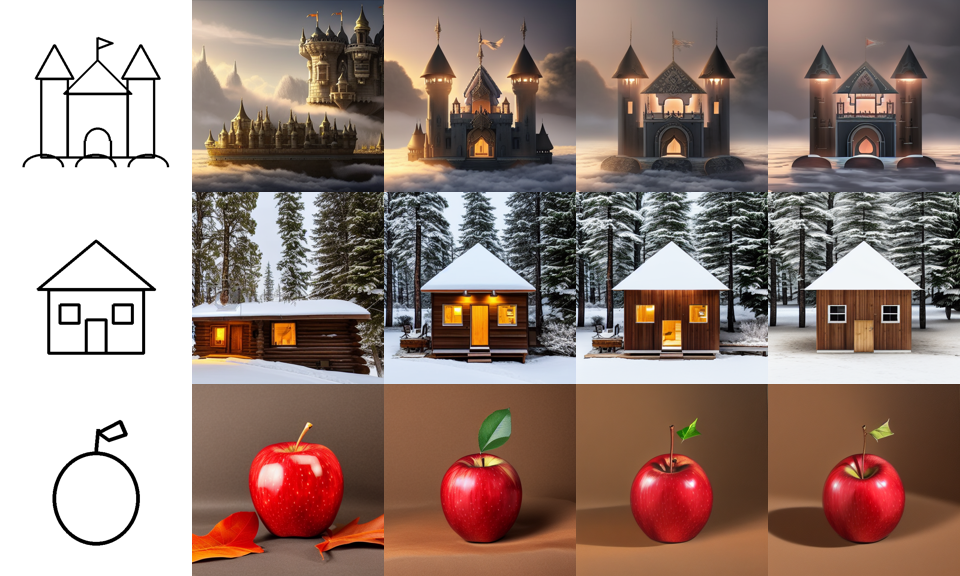

In [11]:
import json
import numpy as np
from PIL import Image, ImageDraw, ImageOps

def _closed(d, pts, w):
    d.line(pts + [pts[0]], fill=0, width=w, joint="curve")

def make_house_sketch(size=512, w=8):
    img = Image.new("RGB", (size, size), "white"); d = ImageDraw.Draw(img)
    _closed(d, [(130, 260), (382, 260), (382, 430), (130, 430)], w)   # walls
    _closed(d, [(100, 260), (256, 130), (412, 260)], w)               # roof
    _closed(d, [(230, 340), (282, 340), (282, 430), (230, 430)], w)   # door
    _closed(d, [(160, 300), (210, 300), (210, 350), (160, 350)], w)   # left window
    _closed(d, [(302, 300), (352, 300), (352, 350), (302, 350)], w)   # right window
    return img

def make_apple_sketch(size=512, w=10):
    img = Image.new("RGB", (size, size), "white"); d = ImageDraw.Draw(img)
    d.ellipse([140, 180, 372, 430], outline=0, width=w)               # body
    d.line([(256, 185), (262, 120)], fill=0, width=w)                 # stem
    _closed(d, [(262, 130), (320, 100), (335, 135), (290, 150)], w)   # leaf
    return img

TEST_SKETCHES = {   # all black-on-white, as the UI would hand them over
    "castle": (ImageOps.invert(make_castle_sketch()),
               "A floating fantasy castle above the clouds, cinematic lighting, detailed concept art"),
    "house":  (make_house_sketch(),
               "a cozy wooden cabin in a snowy forest, warm light in the windows"),
    "apple":  (make_apple_sketch(),
               "a shiny red apple with a stem and a leaf, studio photo"),
}

records, images = [], {}

def run_case(name, seed, steps, scale):
    sketch, prompt = TEST_SKETCHES[name]
    key = f"{name}_seed{seed}_steps{steps}_scale{scale}"
    rec = {"id": key, "sketch": name, "seed": seed, "steps": steps, "scale": scale}
    try:
        img, _, info = generate(sketch, prompt, "None", steps, scale, seed, out_dir="eval_outputs")
        images[key] = img
        rec.update(seconds=info["seconds"], peak_vram_gib=info["peak_vram_gib"])
    except Exception as e:                       # record failures instead of hiding them
        rec["error"] = repr(e)
    records.append(rec)

for name in TEST_SKETCHES:
    for seed in (42, 7):
        for scale in (0.0, 0.5, 1.0, 1.5):
            run_case(name, seed, 25, scale)
    for steps in (10, 40):                       # 25 steps at scale 1.0 is already covered
        run_case(name, 42, steps, 1.0)

# Reproducibility: rerun one configuration and compare pixels with the first run
again, _, _ = generate(*TEST_SKETCHES["castle"], "None", 25, 1.0, 42, out_dir="eval_outputs") \
    if False else generate(TEST_SKETCHES["castle"][0], TEST_SKETCHES["castle"][1], "None", 25, 1.0, 42, out_dir="eval_outputs")
first = images["castle_seed42_steps25_scale1.0"]
diff = np.abs(np.asarray(again, dtype=np.int16) - np.asarray(first, dtype=np.int16)).max()
print("Reproducibility, max pixel difference on rerun:", diff)

with open("eval_results.json", "w") as f:
    json.dump(records, f, indent=2)

errors = [r for r in records if "error" in r]
print(f"{len(records)} runs, {len(errors)} errors")
for steps in (10, 25, 40):
    t = [r["seconds"] for r in records if r.get("steps") == steps and r.get("scale") == 1.0 and "seconds" in r]
    if t:
        print(f"steps {steps}: mean {np.mean(t):.1f}s over {len(t)} runs")

# Overview grid, seed 42: sketch | scale 0.0 | 0.5 | 1.0 | 1.5
cols = [0.0, 0.5, 1.0, 1.5]
sz = 192
grid = Image.new("RGB", (sz * (len(cols) + 1), sz * len(TEST_SKETCHES)))
for r, name in enumerate(TEST_SKETCHES):
    grid.paste(TEST_SKETCHES[name][0].resize((sz, sz)), (0, r * sz))
    for c, s in enumerate(cols):
        im = images.get(f"{name}_seed42_steps25_scale{s}")
        if im: grid.paste(im.resize((sz, sz)), ((c + 1) * sz, r * sz))
display(grid)

In [12]:
import cv2
import numpy as np
import pandas as pd
import torch
from skimage.morphology import skeletonize
from transformers import CLIPModel, CLIPProcessor

# ---- CLIP image-text cosine similarity ----
clip_id = "openai/clip-vit-base-patch32"
clip_model = CLIPModel.from_pretrained(clip_id).to("cuda").eval()
clip_proc = CLIPProcessor.from_pretrained(clip_id)

def clip_cosine(image, text: str) -> float:
    inputs = clip_proc(text=[text], images=image, return_tensors="pt",
                       padding=True, truncation=True).to("cuda")
    with torch.inference_mode():
        out = clip_model(**inputs)
    return float((out.image_embeds * out.text_embeds).sum(-1))   # embeddings are L2-normalised

# ---- Sketch adherence (edge agreement) ----
def stroke_skeleton(sketch) -> np.ndarray:
    strokes = np.asarray(prepare_control_image(sketch).convert("L")) > 127
    return skeletonize(strokes)

SKELETONS = {name: stroke_skeleton(sk) for name, (sk, _) in TEST_SKETCHES.items()}

def near_edges(image, tol: int = 8) -> np.ndarray:
    gray = cv2.cvtColor(np.asarray(image), cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(cv2.GaussianBlur(gray, (5, 5), 0), 100, 200)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * tol + 1, 2 * tol + 1))
    return cv2.dilate(edges, kernel) > 0

def adherence(skeleton: np.ndarray, near: np.ndarray) -> float:
    return float(near[skeleton].mean())

# ---- Score every saved run ----
rows = []
for rec in records:
    if "error" in rec:
        continue
    img, name = images[rec["id"]], rec["sketch"]
    near = near_edges(img)
    own = adherence(SKELETONS[name], near)
    others = [adherence(SKELETONS[o], near) for o in SKELETONS if o != name]
    rows.append({**rec, "adherence": own, "adherence_other": float(np.mean(others)),
                 "clip_cos": clip_cosine(img, TEST_SKETCHES[name][1])})

df = pd.DataFrame(rows)
df["adherence_gain"] = df["adherence"] - df["adherence_other"]
df.to_csv("eval_metrics.csv", index=False)

print("By control strength (n = 6 images per row):")
print(df.groupby("scale")[["adherence", "adherence_other", "adherence_gain", "clip_cos"]].mean().round(3))
print("\nAdherence gain by sketch and control strength:")
print(df.pivot_table(index="sketch", columns="scale", values="adherence_gain").round(3))
print("\nSteps (scale 1.0, seed 42, n = 3 per row):")
print(df[(df.scale == 1.0) & (df.seed == 42)]
      .groupby("steps")[["seconds", "adherence_gain", "clip_cos"]].mean().round(3))

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

By control strength (n = 6 images per row):
       adherence  adherence_other  adherence_gain  clip_cos
scale                                                      
0.0        0.422            0.455          -0.032     0.332
0.5        0.711            0.406           0.305     0.324
1.0        0.736            0.399           0.336     0.341
1.5        0.765            0.355           0.410     0.316

Adherence gain by sketch and control strength:
scale     0.0    0.5    1.0    1.5
sketch                            
apple   0.012  0.409  0.397  0.404
castle -0.027  0.165  0.242  0.392
house  -0.083  0.340  0.371  0.434

Steps (scale 1.0, seed 42, n = 3 per row):
       seconds  adherence_gain  clip_cos
steps                                   
10       2.633           0.304     0.346
25       6.353           0.386     0.348
40       9.677           0.390     0.349


In [13]:
d25 = df[df.steps == 25]
piv_gain = d25.pivot_table(index=["sketch", "seed"], columns="scale", values="adherence_gain")
piv_clip = d25.pivot_table(index=["sketch", "seed"], columns="scale", values="clip_cos")

for a, b in [(0.0, 0.5), (0.5, 1.0), (1.0, 1.5)]:
    d = piv_gain[b] - piv_gain[a]
    print(f"gain {a}->{b}: mean {d.mean():+.3f}, std {d.std():.3f}, "
          f"increased in {(d > 0).sum()}/{len(d)} pairs")
for a, b in [(0.0, 1.0), (1.0, 1.5)]:
    d = piv_clip[b] - piv_clip[a]
    print(f"clip {a}->{b}: mean {d.mean():+.4f}, std {d.std():.4f}, "
          f"increased in {(d > 0).sum()}/{len(d)} pairs")

gain 0.0->0.5: mean +0.337, std 0.157, increased in 6/6 pairs
gain 0.5->1.0: mean +0.021, std 0.077, increased in 5/6 pairs
gain 1.0->1.5: mean +0.084, std 0.133, increased in 4/6 pairs
clip 0.0->1.0: mean +0.0023, std 0.0234, increased in 3/6 pairs
clip 1.0->1.5: mean -0.0183, std 0.0154, increased in 0/6 pairs


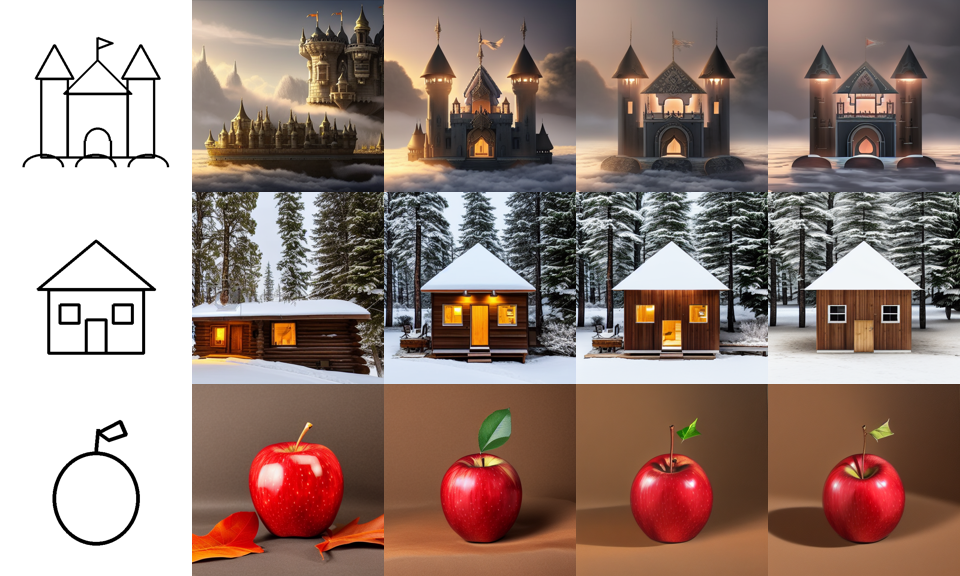

In [14]:
display(grid)

In [15]:
import glob, os, zipfile
from google.colab import files

grid.save("results_grid.png")
paths = ["results_grid.png", "eval_results.json", "eval_metrics.csv"] \
        + glob.glob("eval_outputs/*") + glob.glob("outputs/*")
with zipfile.ZipFile("dreamforge_results.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for p in paths:
        z.write(p)
print(f"{len(paths)} files, {os.path.getsize('dreamforge_results.zip') / 1e6:.1f} MB")
files.download("dreamforge_results.zip")

73 files, 14.8 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
import torch
needed = ["pipe", "generate", "prepare_control_image", "STYLE_PRESETS", "TEST_SKETCHES"]
missing = [n for n in needed if n not in globals()]
print("Missing:", missing or "nothing")
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE (set runtime to T4 GPU)")
import gradio as gr
print("gradio", gr.__version__)
if "pipe" in globals():
    for name, comp in pipe.components.items():
        if isinstance(comp, torch.nn.Module):
            print(f"  {name:16s} {next(comp.parameters()).dtype}")

Missing: nothing
GPU: Tesla T4
gradio 6.31.0
  vae              torch.float16
  text_encoder     torch.float16
  unet             torch.float16
  controlnet       torch.float16
  safety_checker   torch.float16


In [17]:
import gradio as gr
from PIL import ImageOps

try:
    demo.close()                       # stop the old, simple UI if it is still running
except Exception:
    pass

SAVE_OUTPUTS = True                    # your private notebook: keep images. Set False before sharing a public link.

STYLE_CHOICES = [("🎬 Cinematic", "Cinematic concept art"), ("📷 Photoreal", "Photorealistic"),
                 ("🎨 Watercolor", "Watercolor"), ("👾 Pixel art", "Pixel art"), ("⚪ No style", "None")]
assert {v for _, v in STYLE_CHOICES} == set(STYLE_PRESETS)

PROMPT_IDEAS = {"🏰 Sky castle": "A floating fantasy castle above the clouds",
                "🌃 Neon city": "A neon cyberpunk city at night, rain on the streets",
                "🏡 Snow cabin": "A cozy wooden cabin in a snowy forest, warm light in the windows",
                "🍎 Studio apple": "A shiny red apple with a stem and a leaf, studio photo",
                "🌋 Volcano": "A glowing volcano erupting under a starry sky"}

HERO_HTML = """
<div id="df-hero">
  <div class="df-badge">✦ Sketch → Image &nbsp;·&nbsp; Stable Diffusion 1.5 + ControlNet</div>
  <h1>Dream<span>Forge</span> AI</h1>
  <p>Scribble a rough shape. Describe a world. Watch it get forged.</p>
  <div class="df-steps"><span><b>1</b> Sketch</span><i></i><span><b>2</b> Describe</span><i></i><span><b>3</b> Forge</span></div>
</div>"""

HOW_HTML = """
<div class="df-how">
  <div class="df-flow"><span>✏️ Your sketch</span><i>→</i><span>🧼 Clean &amp; invert to white-on-black</span><i>→</i><span>🧭 ControlNet (spatial hints)</span></div>
  <div class="df-flow"><span>💬 Your prompt</span><i>→</i><span>🔤 CLIP tokenizer + text encoder</span><i>→</i><span>🧠 U-Net denoises 25 steps</span><i>→</i><span>🖼️ VAE decoder</span></div>
  <p>The sketch decides <b>where</b> shapes go. The prompt decides <b>what</b> they are. Higher control strength follows your lines more strictly, but can look flatter.</p>
</div>"""

FOOTER_HTML = """
<div id="df-footer">
  <div class="df-models"><span>🤗 stable-diffusion-v1-5</span><span>🤗 control_v11p_sd15_scribble</span><span>🤗 Diffusers</span><span>🔥 PyTorch</span><span>⚡ Gradio</span></div>
  <p>Models: Stable Diffusion v1.5 (CreativeML OpenRAIL-M) and ControlNet v1.1 Scribble (OpenRAIL). Output follows your sketch's rough structure; it is guidance, not a guarantee. A safety checker is enabled.</p>
</div>"""

def card_title(number, text, hint=""):
    hint_html = f"<small>{hint}</small>" if hint else ""
    return f'<div class="df-card-title"><b>{number}</b><span>{text}</span>{hint_html}</div>'

THEME = gr.themes.Base(primary_hue="violet", secondary_hue="cyan", neutral_hue="slate", radius_size="lg",
                       font=[gr.themes.GoogleFont("Inter"), "ui-sans-serif", "system-ui", "sans-serif"])

CSS = """
:root, .gradio-container, .dark {
  --body-background-fill: #07050f; --background-fill-primary: #0d0a1c; --background-fill-secondary: #120e26;
  --block-background-fill: rgba(255,255,255,0.035); --block-border-color: rgba(255,255,255,0.09);
  --border-color-primary: rgba(255,255,255,0.12); --body-text-color: #ece9ff; --body-text-color-subdued: #a79fd6;
  --block-title-text-color: #cfc8ff; --block-label-text-color: #b9b0ee; --block-label-background-fill: transparent;
  --input-background-fill: rgba(255,255,255,0.05); --input-border-color: rgba(255,255,255,0.14);
  --input-border-color-focus: #8b5cf6; --color-accent: #8b5cf6; --slider-color: #8b5cf6;
  --shadow-drop: none; --shadow-drop-lg: none;
}
.gradio-container { max-width: 1280px !important; margin: 0 auto !important;
  background: radial-gradient(1100px 560px at 8% -8%, rgba(124,58,237,.38), transparent 60%),
              radial-gradient(900px 520px at 96% 2%, rgba(6,182,212,.28), transparent 58%),
              radial-gradient(900px 600px at 50% 110%, rgba(236,72,153,.16), transparent 60%), #07050f !important; }
#df-hero { text-align: center; padding: 34px 10px 10px; }
#df-hero .df-badge { display: inline-block; padding: 6px 14px; border-radius: 999px; font-size: .82rem; color: #cbbcff;
  background: rgba(139,92,246,.14); border: 1px solid rgba(139,92,246,.4); letter-spacing: .02em; }
#df-hero h1 { margin: 16px 0 6px; font-weight: 800; letter-spacing: -0.035em; line-height: 1.02;
  font-size: clamp(2.6rem, 7vw, 4.8rem); color: #fff; }
#df-hero h1 span { background: linear-gradient(90deg, #a78bfa, #22d3ee, #f472b6, #a78bfa); background-size: 300% 100%;
  -webkit-background-clip: text; background-clip: text; -webkit-text-fill-color: transparent; animation: df-shift 8s linear infinite; }
#df-hero p { color: #b8b0e6; font-size: 1.12rem; margin: 0 0 18px; }
.df-steps { display: inline-flex; align-items: center; gap: 10px; flex-wrap: wrap; justify-content: center; }
.df-steps span { display: inline-flex; align-items: center; gap: 8px; padding: 6px 14px 6px 6px; border-radius: 999px;
  background: rgba(255,255,255,.05); border: 1px solid rgba(255,255,255,.1); color: #e6e1ff; font-size: .92rem; }
.df-steps span b { display: inline-grid; place-items: center; width: 24px; height: 24px; border-radius: 50%;
  background: linear-gradient(135deg, #7c3aed, #06b6d4); color: #fff; font-size: .8rem; }
.df-steps i { width: 26px; height: 1px; background: linear-gradient(90deg, #7c3aed, #06b6d4); }
@keyframes df-shift { to { background-position: 300% 0; } }
.df-card { background: rgba(255,255,255,.04) !important; border: 1px solid rgba(255,255,255,.09) !important;
  border-radius: 22px !important; padding: 16px !important; backdrop-filter: blur(14px);
  box-shadow: 0 10px 40px rgba(0,0,0,.35) !important; gap: 12px !important; }
.df-card-title { display: flex; align-items: center; gap: 10px; font-weight: 700; font-size: 1.05rem; color: #fff; }
.df-card-title b { display: inline-grid; place-items: center; width: 26px; height: 26px; border-radius: 8px;
  background: linear-gradient(135deg, #7c3aed, #06b6d4); font-size: .85rem; }
.df-card-title small { margin-left: auto; color: #9d94d6; font-weight: 500; font-size: .8rem; }
.df-chips { gap: 8px !important; flex-wrap: wrap !important; }
.df-chip, .df-starter { border-radius: 999px !important; border: 1px solid rgba(255,255,255,.14) !important;
  background: rgba(255,255,255,.05) !important; color: #e6e1ff !important; font-size: .85rem !important;
  min-width: 0 !important; flex: 0 0 auto !important; transition: transform .15s, border-color .15s, background .15s; }
.df-chip:hover, .df-starter:hover { transform: translateY(-2px); border-color: #8b5cf6 !important; background: rgba(139,92,246,.18) !important; }
.df-styles label { border-radius: 999px !important; border: 1px solid rgba(255,255,255,.14) !important;
  background: rgba(255,255,255,.05) !important; padding: 7px 14px !important; cursor: pointer; transition: transform .15s, background .15s; }
.df-styles label:hover { transform: translateY(-1px); }
.df-styles label.selected { background: linear-gradient(135deg, #7c3aed, #0891b2) !important; border-color: transparent !important; color: #fff !important; }
.df-styles input[type=radio] { display: none !important; }
#df-forge-btn { min-height: 58px; font-size: 1.15rem !important; font-weight: 700 !important; letter-spacing: .02em;
  border: none !important; color: #fff !important; border-radius: 16px !important;
  background: linear-gradient(120deg, #7c3aed, #06b6d4 60%, #ec4899) !important; background-size: 200% 100% !important;
  box-shadow: 0 0 0 0 rgba(139,92,246,.6), 0 10px 30px rgba(124,58,237,.45) !important;
  animation: df-pulse 2.6s ease-in-out infinite; transition: transform .15s; }
#df-forge-btn:hover { transform: translateY(-2px) scale(1.01); background-position: 100% 0 !important; }
@keyframes df-pulse { 50% { box-shadow: 0 0 0 10px rgba(139,92,246,0), 0 10px 40px rgba(6,182,212,.5); } }
.df-how { color: #c9c2f0; font-size: .92rem; line-height: 1.6; }
.df-flow { display: flex; align-items: center; gap: 8px; flex-wrap: wrap; margin: 8px 0; }
.df-flow span { padding: 6px 12px; border-radius: 12px; background: rgba(255,255,255,.06); border: 1px solid rgba(255,255,255,.1); }
.df-flow i { color: #22d3ee; font-style: normal; }
#df-footer { text-align: center; padding: 14px 6px 28px; color: #8f87c4; font-size: .82rem; }
.df-models { display: flex; gap: 8px; justify-content: center; flex-wrap: wrap; margin-bottom: 10px; }
.df-models span { padding: 5px 12px; border-radius: 999px; background: rgba(255,255,255,.05);
  border: 1px solid rgba(255,255,255,.1); color: #cfc8ff; font-size: .8rem; }
footer { opacity: .5; }
"""

STARTERS = {name: sk for name, (sk, _) in TEST_SKETCHES.items()}

def run_generation(sketch, prompt, style, steps, strength, seed, guidance):
    return generate(sketch, prompt, style, steps, strength, seed, guidance,
                    out_dir="outputs" if SAVE_OUTPUTS else None)

def forge(sketch, prompt, style, steps, strength, guidance, random_seed, seed, history,
          progress=gr.Progress(track_tqdm=True)):
    use_seed = -1 if random_seed else int(seed)
    try:
        image, control, settings = run_generation(sketch, prompt, style, steps, strength, use_seed, guidance)
    except (ValueError, RuntimeError) as e:
        raise gr.Error(str(e))
    caption = f"{settings['seed']} · {settings['steps']} steps · control {settings['controlnet_conditioning_scale']}"
    history = ([(image, caption)] + (history or []))[:12]
    before = ImageOps.invert(control.convert("L")).convert("RGB")      # dark lines on white, for the slider
    return (before, image), control, settings, history, history

with gr.Blocks(title="DreamForge AI · sketch to image") as demo:
    gr.HTML(HERO_HTML)
    history_state = gr.State([])
    with gr.Row(equal_height=False):
        with gr.Column(scale=5, elem_classes="df-card"):
            gr.HTML(card_title("1", "Sketch", "draw dark lines, or try a starter"))
            with gr.Row(elem_classes="df-chips"):
                b_castle = gr.Button("🏰 Castle", size="sm", elem_classes="df-starter")
                b_house = gr.Button("🏠 Cabin", size="sm", elem_classes="df-starter")
                b_apple = gr.Button("🍎 Apple", size="sm", elem_classes="df-starter")
            sketch = gr.Sketchpad(label="Canvas", show_label=False)
            with gr.Accordion("…or upload a line drawing", open=False):
                gr.Markdown("Dark lines on a light background work best. Photos are not sketches.")
                uploaded = gr.Image(label="Upload", type="numpy", show_label=False)

            gr.HTML(card_title("2", "Describe"))
            prompt = gr.Textbox(show_label=False, lines=2, placeholder="Describe what your sketch should become…",
                                value=PROMPT_IDEAS["🏰 Sky castle"])
            with gr.Row(elem_classes="df-chips"):
                idea_buttons = [(gr.Button(label, size="sm", elem_classes="df-chip"), text)
                                for label, text in PROMPT_IDEAS.items()]
            style = gr.Radio(STYLE_CHOICES, value="Cinematic concept art", label="Style", elem_classes="df-styles")

            with gr.Accordion("⚙️ Fine-tune", open=False):
                strength = gr.Slider(0.0, 2.0, value=1.0, step=0.1, label="Sketch strictness (control strength)",
                                     info="0 ignores the sketch. About 0.5 to 1.2 works well.")
                steps = gr.Slider(10, 50, value=25, step=1, label="Quality steps",
                                  info="More steps cost more time; gains flatten around 25.")
                guidance = gr.Slider(1.0, 15.0, value=7.5, step=0.5, label="Prompt strength (guidance)")
                random_seed = gr.Checkbox(value=True, label="🎲 Random seed")
                seed = gr.Number(value=42, precision=0, label="Seed (used when random is off)")

            gr.HTML(card_title("3", "Forge"))
            forge_btn = gr.Button("✦  Forge my image", variant="primary", elem_id="df-forge-btn")

        with gr.Column(scale=6, elem_classes="df-card"):
            gr.HTML(card_title("✦", "Your creation", "drag the slider: sketch ⇄ result"))
            out_slider = gr.ImageSlider(show_label=False, height=520)
            with gr.Tabs():
                with gr.Tab("🧭 AI view"):
                    out_control = gr.Image(show_label=False, interactive=False, height=300)
                with gr.Tab("🧾 Settings"):
                    out_settings = gr.JSON(show_label=False)
                with gr.Tab("🧠 How"):
                    gr.HTML(HOW_HTML)
            gallery = gr.Gallery(label="Forge history (compare settings)", columns=4, rows=1, height=220,
                                 object_fit="cover")
    gr.HTML(FOOTER_HTML)

    b_castle.click(lambda: STARTERS["castle"], None, sketch)
    b_house.click(lambda: STARTERS["house"], None, sketch)
    b_apple.click(lambda: STARTERS["apple"], None, sketch)
    for btn, text in idea_buttons:
        btn.click(lambda t=text: t, None, prompt)

    forge_btn.click(
        lambda drawn, up, *rest: forge(up if up is not None else drawn, *rest),
        inputs=[sketch, uploaded, prompt, style, steps, strength, guidance, random_seed, seed, history_state],
        outputs=[out_slider, out_control, out_settings, gallery, history_state])

demo.queue(max_size=8).launch(theme=THEME, css=CSS, share=True)

Closing server running on port: 7860
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8778c83dfa3f479c28.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
